In [1]:
#Generate a new spectrum


In [2]:
import numpy as np
import matplotlib.pyplot as plt

#Generate wavelengths from 1600 to 1700nm
wavelengths = np.linspace(1600, 1700, 1800)

#parametres of our simplified absorption feature
center = 1650
width = 5

#Gaussian-shaped absorption profile
absorption = np.exp(
    -0.5 * ((wavelengths - center) / width) ** 2
)

print("Number of simulated wavelengths:", len(wavelengths))
print("Minimum wavelength:", wavelengths.min())
print("Maximum wavelength:", wavelengths.max())

Number of simulated wavelengths: 1800
Minimum wavelength: 1600.0
Maximum wavelength: 1700.0


In [4]:
#Experiment B — Compare different absorption strengths

(0.0, 1.05)

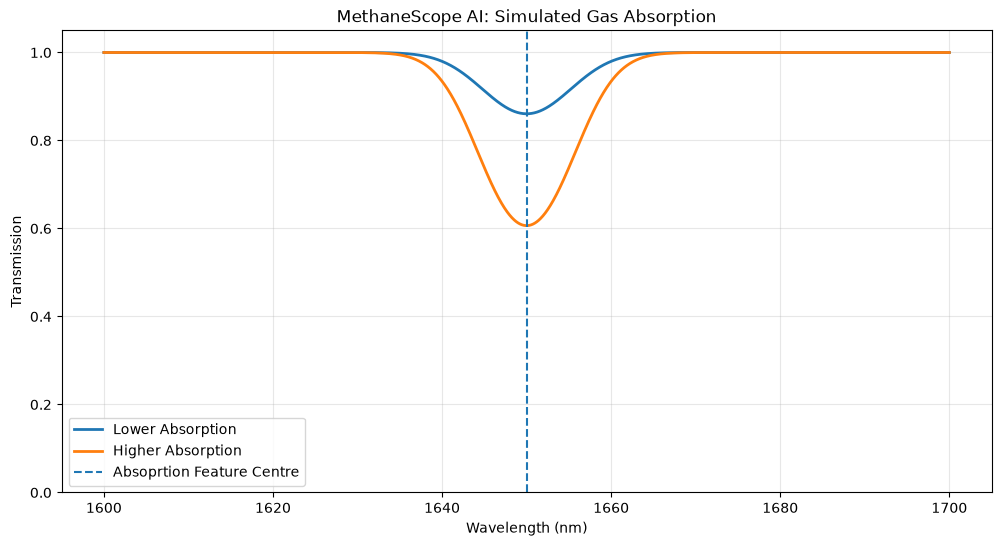

In [6]:
# Two illustrative optical depth strengths
low_optical_depth  = 0.15 * absorption 
high_optical_depth = 0.50 * absorption

#Beer-Lambert transmission 
low_transmission = np.exp(-low_optical_depth)
high_transmission = np.exp(-high_optical_depth)

#visualise the results
plt.figure(figsize = (12,6))

plt.plot(
    wavelengths,
    low_transmission,
    label="Lower Absorption",
    linewidth = 2
)

plt.plot(
    wavelengths,
    high_transmission,
    label ="Higher Absorption",
    linewidth = 2
)

plt.axvline(
    1650,
    linestyle="--",
    label="Absoprtion Feature Centre"
)

plt.xlabel("Wavelength (nm)")
plt.ylabel("Transmission")
plt.title("MethaneScope AI: Simulated Gas Absorption")

plt.legend()
plt.grid(alpha=0.3)
plt.ylim(0, 1.05)

In [7]:
#Experiment C — Interpret the measurements

In [8]:
import pandas as pd

# Find the wavelength nearest our feature centre
index = np.argmin(np.abs(wavelengths - 1650))

results = pd.DataFrame({
    "Scenario": [
        "Lower Absorption",
        "Higher Absorption"
    ],
    "Optical Depth": [
        low_optical_depth[index],
        high_optical_depth[index]
    ],
    "Transmission": [
        low_transmission[index],
        high_transmission[index]
    ]
})

print(results.round(4).to_string(index=False))

         Scenario  Optical Depth  Transmission
 Lower Absorption           0.15        0.8607
Higher Absorption           0.50        0.6065


In [9]:
#Experiment - Simulate satelite measurement noise

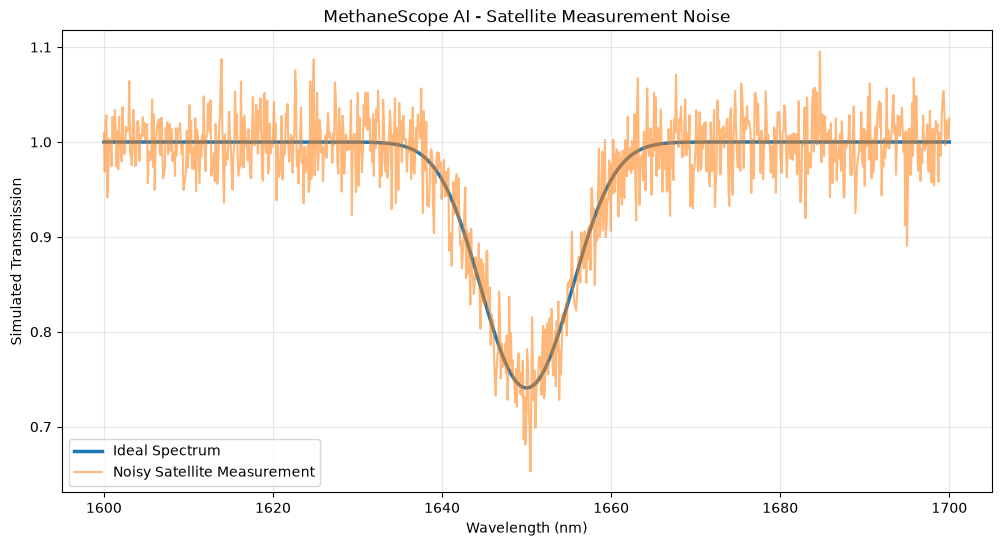

Noise standard deviation: 0.03
Samples: 1000
Minimum ideal transmission: 0.7408


In [11]:
import numpy as np
import matplotlib.pyplot as plt

# Generate reproducible random measurements
rng = np.random.default_rng(42)

# Simulated wavelength range
wavelengths = np.linspace(1600, 1700, 1000)

# Simplified atmospheric absorption feature
center = 1650
width = 5
optical_depth = 0.3

profile = np.exp(
    -0.5 * ((wavelengths - center) / width) ** 2
)

# Ideal atmospheric transmission
clean_spectrum = np.exp(-optical_depth * profile)

# Add simulated instrument noise
noise_std = 0.03

noise = rng.normal(
    loc=0,
    scale=noise_std,
    size=len(wavelengths)
)

noisy_spectrum = clean_spectrum + noise

# Visualise both measurements
plt.figure(figsize=(12, 6))

plt.plot(
    wavelengths,
    clean_spectrum,
    label="Ideal Spectrum",
    linewidth=2.5
)

plt.plot(
    wavelengths,
    noisy_spectrum,
    label="Noisy Satellite Measurement",
    alpha=0.55
)

plt.xlabel("Wavelength (nm)")
plt.ylabel("Simulated Transmission")
plt.title("MethaneScope AI - Satellite Measurement Noise")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

print("Noise standard deviation:", noise_std)
print("Samples:", len(wavelengths))
print("Minimum ideal transmission:", round(clean_spectrum.min(), 4))

In [12]:
#Investigate noise levels

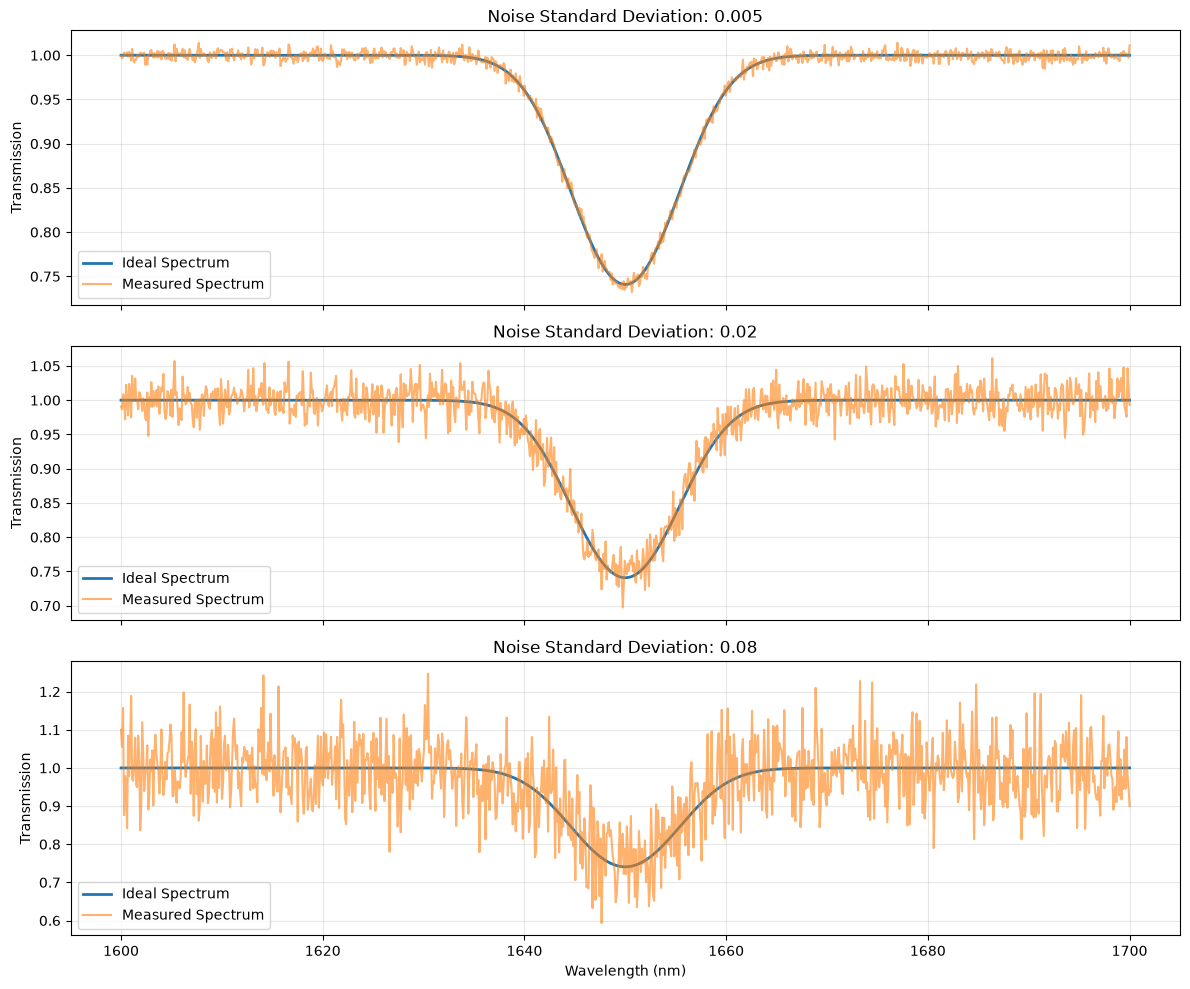

In [13]:
noise_levels = [0.005, 0.02, 0.08]

fig, axes = plt.subplots(
    3, 1,
    figsize=(12, 10),
    sharex=True
)

for ax, noise_level in zip(axes, noise_levels):

    simulated_noise = rng.normal(
        0,
        noise_level,
        size=len(wavelengths)
    )

    measurement = clean_spectrum + simulated_noise

    ax.plot(
        wavelengths,
        clean_spectrum,
        label="Ideal Spectrum",
        linewidth=2
    )

    ax.plot(
        wavelengths,
        measurement,
        label="Measured Spectrum",
        alpha=0.6
    )

    ax.set_title(f"Noise Standard Deviation: {noise_level}")
    ax.set_ylabel("Transmission")
    ax.grid(alpha=0.3)
    ax.legend()

axes[-1].set_xlabel("Wavelength (nm)")

plt.tight_layout()
plt.show()